In [63]:
import pandas as pd 
from matplotlib import pyplot as plt
# import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\rose odiwuor\OneDrive\Documents\Lux Projects\food_prices_kenya\data\food_prices_kenya.csv")

df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [2]:
df.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [4]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [5]:
df.sample(20)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1048,2017-03-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,68.60,0.67
1218,2012-12-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,50.40,0.59
113,2019-08-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,115.00,1.11
2138,2015-11-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2280.00,22.29
1739,2015-02-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,5760.00,62.95
998,2012-12-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,80.00,0.93
446,2018-08-15,NaN,NaN,Hola,Maize,Retail,KG,48.00,0.48
2730,2019-01-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,1500.00,14.75
2626,2015-03-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,2403.33,26.16
1780,2018-08-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4762.00,47.29


In [6]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

In [7]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(10, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
Name: date, dtype: datetime64[us]

In [8]:
# extract and add year and month columns
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

In [9]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
2575,2010-12-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,1792.00,22.30,2010,12
2150,2016-11-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2495.00,24.56,2016,11
1453,2018-11-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,7200.00,69.84,2018,11
2317,2016-12-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,3000.00,29.37,2016,12
817,2011-09-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,65.55,0.69,2011,9


In [10]:
# fill the missing county and region for the market that has none

In [11]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [12]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [13]:
# How many rows, markets and commodities does the file have, and what are the first and last dates?
df.shape 
# 2742 rows

(2742, 11)

In [14]:
highest_date = df['date'].max()
lowest_date = df['date'].min()

print(highest_date)         # 2019-12-15
print(lowest_date)          # 2015-02-15 , should be 2006 not 2015

2019-12-15 00:00:00
2006-01-15 00:00:00


In [15]:
import numpy as np

In [16]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""
# df_wholesale = df[df["price_type"] == "wholesale" and df["unit"] == "90 KG"].copy()
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()

# df["price_per_kg"] = np.where(df["price_type"] == "wholesale", df["price"] / 90, df["price"])
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [17]:
#we are finding the price for a single kg of maize by dividing the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [18]:
df_wholesale.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
2380,2008-05-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,1912.38,30.52,2008,5
1325,2008-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3880.00,55.31,2008,2
1869,2012-03-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,5950.00,72.38,2012,3
1620,2018-12-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,7200.00,70.31,2018,12
1943,2018-06-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6918.75,68.43,2018,6


In [19]:
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [20]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [21]:
#average for the maize commodity in the wholesale sales_price_per_kg
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(28.54230389890584)

In [22]:
#average for the maize commodity in the retail sales_price_per_kg
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [ ]:
"""
Maize prices over the years
Calculate the average wholesale maize price per bag for each year and the year-on-year change. 
Plot the yearly average as a line chart with the price in KES on the y-axis.

Which year had the highest average wholesale maize price?
Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?
"""

In [25]:
df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.244444
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.488889
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.913556
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.188889
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.058444


In [45]:
yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round()
yearly_avg

,year,price_kes
0,2006,1395.0
1,2007,1207.0
2,2008,1906.0
3,2009,2513.0
4,2010,1774.0
5,2011,3020.0
6,2012,3174.0
7,2013,2962.0
8,2014,2994.0
9,2015,2690.0


In [46]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.0
1,2007,1207.0
2,2008,1906.0
3,2009,2513.0
4,2010,1774.0
5,2011,3020.0
6,2012,3174.0
7,2013,2962.0
8,2014,2994.0
9,2015,2690.0


In [47]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.0,NaN
1,2007,1207.0,-188.0
2,2008,1906.0,699.0
3,2009,2513.0,607.0
4,2010,1774.0,-739.0
5,2011,3020.0,1246.0
6,2012,3174.0,154.0
7,2013,2962.0,-212.0
8,2014,2994.0,32.0
9,2015,2690.0,-304.0


In [48]:
yearly_avg.max()

year              2019.0
avg_price_kes     3744.0
yoy_change_kes    1246.0
dtype: float64

In [49]:
yearly_avg.min()

year              2006.0
avg_price_kes     1207.0
yoy_change_kes   -1336.0
dtype: float64

In [50]:
yearly_avg["avg_price_kes"].max()


np.float64(3744.0)

In [51]:
yearly_avg["yoy_change_kes"].max()


np.float64(1246.0)

In [52]:
yearly_avg["yoy_change_kes"].min()

np.float64(-1336.0)

In [53]:
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax()]

year              2017.0
avg_price_kes     3744.0
yoy_change_kes     981.0
Name: 11, dtype: float64

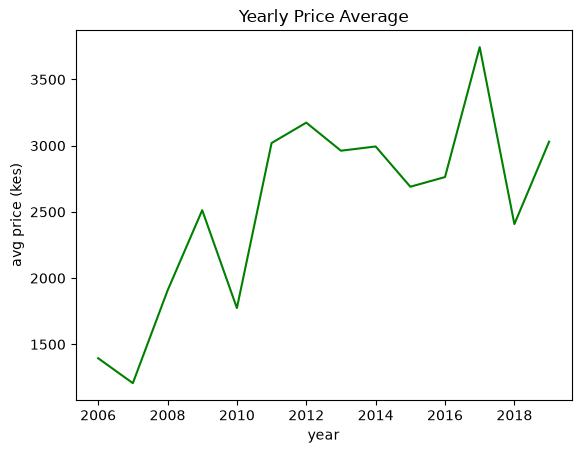

In [62]:
# Plot the yearly average as a line chart with the price in KES on the y-axis.
# x axis -> year
# y axis -> avg_price_kes

plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="green")
plt.title("Yearly Price Average")
plt.xlabel("year")
plt.ylabel("avg price (kes)")
plt.show()

In [70]:
print(f"Highest wholesale price year: {yearly_avg.loc[yearly_avg['avg_price_kes'].idxmax(), 'year']}")
# # Highest wholesale price year: 2017
# # Biggest rise: 2011
# # Biggest fall: 2018

# yearly_avg.loc[yearly_avg['avg_price_kes'].idxmax(), 'year']

Highest wholesale price year: 2017
